<a href="https://colab.research.google.com/github/wandia-123/kenya-maize-yield-analysis/blob/main/Maize_Yield_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("Maize_produce_1961-2024.csv")

In [7]:

df = df[["Year", "Value", "Flag"]].rename(columns={"Value": "yield_kg_ha"})
df["yield_t_ha"] = df["yield_kg_ha"] / 1000

print(df.sort_values("yield_t_ha").head(5))
print(df.sort_values("yield_t_ha").tail(5))



    Year  yield_kg_ha Flag  yield_t_ha
4   1965       1071.3    X      1.0713
5   1966       1079.2    E      1.0792
3   1964       1171.4    E      1.1714
6   1967       1200.0    E      1.2000
19  1980       1200.0    E      1.2000
    Year  yield_kg_ha Flag  yield_t_ha
27  1988       1903.0    A      1.9030
43  2004       1929.3    A      1.9293
25  1986       2034.3    A      2.0343
33  1994       2040.0    A      2.0400
21  1982       2071.2    A      2.0712


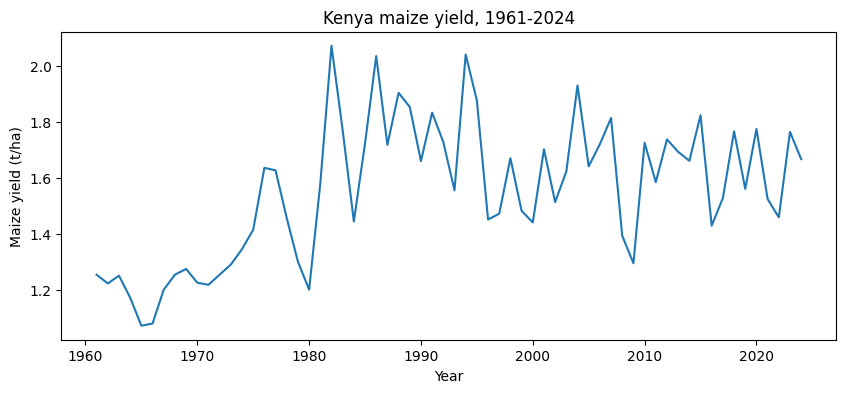

In [8]:
plt.figure(figsize=(10, 4))
plt.plot(df["Year"], df["yield_t_ha"])
plt.xlabel("Year"); plt.ylabel("Maize yield (t/ha)")
plt.title("Kenya maize yield, 1961-2024")
plt.show()

In [10]:
# Average yield per decade
df["decade"] = (df["Year"] // 10) * 10
print(df.groupby("decade")["yield_t_ha"].agg(["mean", "std", "min", "max"]))

# Does data quality differ by flag?
print(df.groupby("Flag")["yield_t_ha"].agg(["count", "mean"]))

# Year-on-year change, to spot sharp drops
df["change_pct"] = df["yield_t_ha"].pct_change() * 100
print(df.sort_values("change_pct").head(5)[["Year", "yield_t_ha", "change_pct"]])

            mean       std     min     max
decade                                    
1960    1.197233  0.075914  1.0713  1.2741
1970    1.376150  0.154417  1.2174  1.6352
1980    1.729170  0.266985  1.2000  2.0712
1990    1.676240  0.195756  1.4506  2.0400
2000    1.606570  0.197180  1.2943  1.9293
2010    1.650230  0.122456  1.4284  1.8230
2020    1.637160  0.141751  1.4583  1.7741
      count      mean
Flag                 
A        47  1.666487
E        16  1.246769
X         1  1.071300
    Year  yield_t_ha  change_pct
47  2008      1.3925  -23.202074
35  1996      1.4506  -22.671784
55  2016      1.4284  -21.645639
23  1984      1.4437  -18.398146
26  1987      1.7169  -15.602419


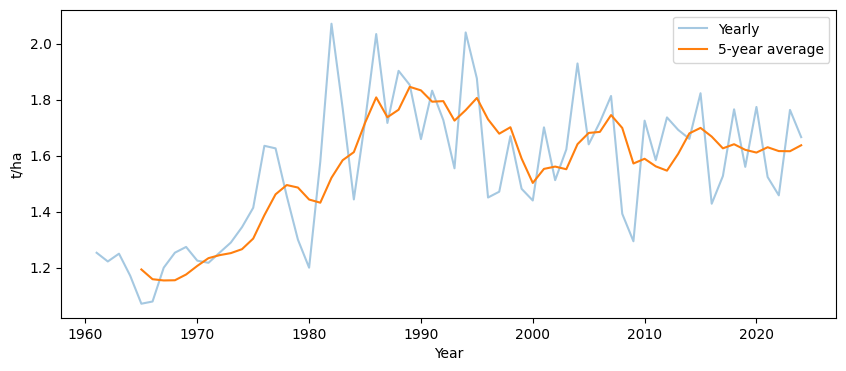

In [11]:
df["rolling_5yr"] = df["yield_t_ha"].rolling(5).mean()
plt.figure(figsize=(10, 4))
plt.plot(df["Year"], df["yield_t_ha"], alpha=0.4, label="Yearly")
plt.plot(df["Year"], df["rolling_5yr"], label="5-year average")
plt.legend(); plt.xlabel("Year"); plt.ylabel("t/ha"); plt.show()

In [15]:
with open("your_power_file.csv") as f:
    for i, line in enumerate(f):
        if i < 25: print(i, line.rstrip())

0 -BEGIN HEADER-
1 NASA/POWER Source Native Resolution Monthly and Annual
2 Dates (month/day/year): 01/01/1981 through 12/31/2024 in LST
3 Location: Latitude  1.02   Longitude 35.0
4 Elevation from MERRA-2: Average for 0.5 x 0.625 degree lat/lon region = 2097.62 meters
5 The value for missing source data that cannot be computed or is outside of the sources availability range: -999
6 Parameter(s):
7 PRECTOTCORR         MERRA-2 Precipitation Corrected (mm/day)
8 PRECTOTCORR_SUM     MERRA-2 Precipitation Corrected Sum (mm/day)
9 -END HEADER-
10 PARAMETER,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANN
11 PRECTOTCORR,1981,0.24,0.4,12.47,11.22,7.55,3.52,6.36,9.4,6.56,3.55,2.99,1.17,5.49
12 PRECTOTCORR,1982,1.28,1.45,1.4,13.16,11.89,3.88,4.64,8.93,3.23,7.81,6.6,1.87,5.53
13 PRECTOTCORR,1983,0.65,2.62,0.77,4.84,10.55,6.97,5.87,9.88,6.46,6.42,4.92,2.26,5.2
14 PRECTOTCORR,1984,0.14,0.33,0.35,3.98,4.83,5.32,5.29,5.86,5.09,5.13,5.16,0.9,3.53
15 PRECTOTCORR,1985,2.03,1.66,4.93,9.82,12.8,4

In [16]:
w = pd.read_csv("your_power_file.csv", skiprows=10)
print(w["PARAMETER"].unique())

rain = w[w["PARAMETER"] == "PRECTOTCORR"][["YEAR", "ANN"]].rename(
    columns={"YEAR": "Year", "ANN": "rain_mm_day"})

print((rain["rain_mm_day"] == -999).sum())   # should print 0
rain["rain_mm_year"] = rain["rain_mm_day"] * 365

data = df.merge(rain, on="Year")
print(data.shape)        # expect (44, ...)
print(data[["yield_t_ha", "rain_mm_year"]].corr())

['PRECTOTCORR' 'PRECTOTCORR_SUM']
0
(44, 9)
              yield_t_ha  rain_mm_year
yield_t_ha      1.000000      0.278055
rain_mm_year    0.278055      1.000000


In [17]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

X = data[["rain_mm_year"]].values
y = data["yield_t_ha"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

model = LinearRegression().fit(X_train, y_train)
pred = model.predict(X_test)

print("Slope:", model.coef_[0], "Intercept:", model.intercept_)
print("Test RMSE (t/ha):", np.sqrt(mean_squared_error(y_test, pred)))
print("Test R2:", r2_score(y_test, pred))

# Baseline- predict the training mean
base = np.full_like(y_test, y_train.mean())
print("Baseline RMSE:", np.sqrt(mean_squared_error(y_test, base)))

Slope: 0.0001138073713735528 Intercept: 1.4626570824128917
Test RMSE (t/ha): 0.1156673650959996
Test R2: 0.18149563826715764
Baseline RMSE: 0.12856703799913655


Max difference from sklearn: 6.661338147750939e-16
GD test RMSE: 0.11566736509599959


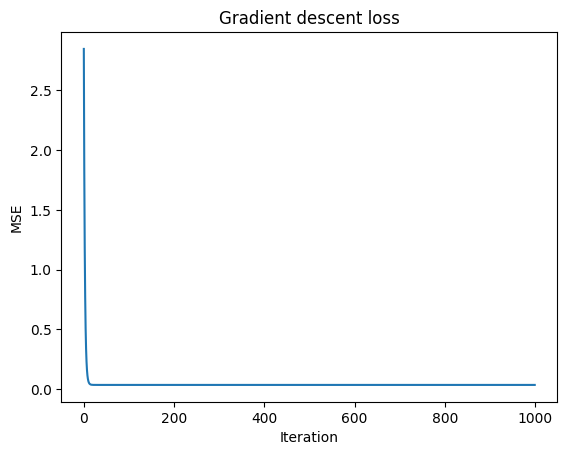

In [18]:
# Standardise the feature, otherwise gradient descent behaves badly
mu, sd = X_train.mean(), X_train.std()
Xb = np.c_[np.ones(len(X_train)), (X_train - mu) / sd]   # column of 1s = intercept

w = np.zeros(2)
lr, n = 0.1, len(y_train)
losses = []

for i in range(1000):
    err = Xb @ w - y_train
    grad = (2 / n) * Xb.T @ err        # gradient of mean squared error
    w -= lr * grad
    losses.append(np.mean(err ** 2))

Xt = np.c_[np.ones(len(X_test)), (X_test - mu) / sd]
pred_gd = Xt @ w

print("Max difference from sklearn:", np.max(np.abs(pred_gd - pred)))   # should be near 0
print("GD test RMSE:", np.sqrt(mean_squared_error(y_test, pred_gd)))

plt.plot(losses); plt.xlabel("Iteration"); plt.ylabel("MSE"); plt.title("Gradient descent loss"); plt.show()

In [19]:
from sklearn.model_selection import cross_val_score
print(data[["yield_t_ha", "rain_mm_year"]].corr())
print(cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2"))

              yield_t_ha  rain_mm_year
yield_t_ha      1.000000      0.278055
rain_mm_year    0.278055      1.000000
[-4.48147995e-01  3.89321217e-02 -3.42665874e-04 -1.63787001e-01
 -6.25736607e+00]
